In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def plotComparisonHeatmap(df_comparison,region,save_extension="png",vmax=1):
    '''
    save_extension: "png","svg"
    '''
    
    fig,ax = plt.subplots(1,1,figsize=(7,7))

    label = r"Mean $\Delta$F/F"
        
    sns.heatmap(df_comparison,ax=ax,cmap="seismic",center=0,vmin=-1,vmax=vmax,square=True,cbar=True,cbar_kws={"label":label})
    
    ax.axhline(5,color="k",ls="--")
    ax.axvline(1,color="k",ls="--",alpha=0.25)
    ax.axvline(2,color="k",ls="--",alpha=0.25)
    
    ax.set_xticklabels(["Pre-feeding","Feeding","0-5 min Post-feeding","5-10 min Post-feeding","10-15 min Post-feeding","15-20 min Post-feeding","20-25 min Post-feeding"])
    ax.set_yticklabels([f"Fly {i+1}" for i in range(12)])
    
    ax.set_ylabel("Flies")
    
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)
    
    ax.text(7.5,2.5,"Sucrose",rotation=90,va="center",ha="center")
    ax.text(7.5,8.5,"Sucrose + NHS",rotation=90,va="center",ha="center")
    
    ax.set_title("Genotype: TH(D4) > GCaMP6m \n(Region: " + r"$\gamma$1pedc)")
    
    plt.tight_layout()
    plt.savefig(f"../figures/Sucrose_vs_NHS_response_mean_comparison_heatmap_of_TH_D4_X_GCaMP6m_for_{region}.{save_extension}",dpi=600,transparent=True)

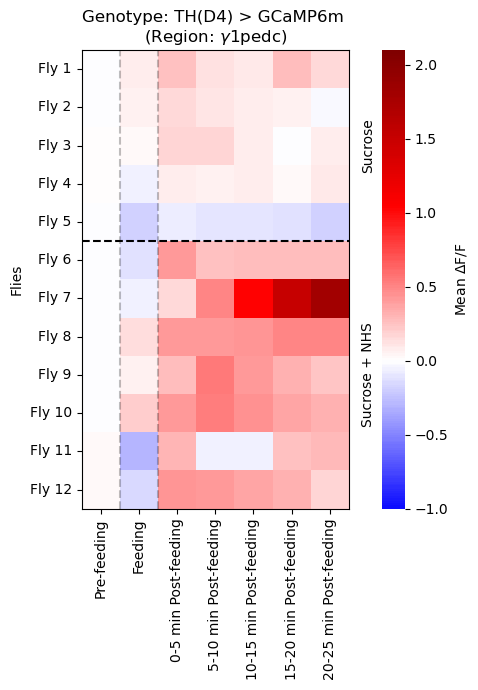

In [3]:
region = "gamma1pedc"

df_data_region_NHS60 = pd.read_csv(f"../csv_files/Brainwise_time_binned_mean_dFF_response_of_{region}_for_NHS60.csv",index_col=0)
df_data_region_Sucrose = pd.read_csv(f"../csv_files/Brainwise_time_binned_mean_dFF_response_of_{region}_for_Sucrose.csv",index_col=0)

mean_cols = ['PreMean','DuringMean','Post1Mean','Post2Mean','Post3Mean','Post4Mean','Post5Mean']

#----------[NHS60]--------------

df_NHS60_mean = df_data_region_NHS60[mean_cols]

#----------[Sucrose]--------------

df_Sucrose_mean = df_data_region_Sucrose[mean_cols]

#----------[Sucrose|NHS60]-----------

df_comparison_mean = pd.concat((df_Sucrose_mean,df_NHS60_mean),axis=0)

vmax = 2.1

#---------[Plot heatmap for mean response]---------------

plotComparisonHeatmap(df_comparison= df_comparison_mean, region = region, save_extension="svg",vmax = vmax)


In [4]:
# Dataframe for figure S13-D
new_index = []
for i,idx in enumerate(df_comparison_mean.index):
    new_index.append(f"{idx}(Fly{i+1})")

df_comparison_mean.index = new_index
df_comparison_mean.to_csv("../csv_files/Sucrose_vs_NHS60_mean_response_comparison_heatmap.csv")
df_comparison_mean

,PreMean,DuringMean,Post1Mean,Post2Mean,Post3Mean,Post4Mean,Post5Mean
AKG_B35(Fly1),0.002778,0.089047,0.254543,0.122551,0.099258,0.280756,0.155144
AKG_B36(Fly2),0.000791,0.065027,0.153437,0.111443,0.084404,0.064843,-0.021978
AKG_B37(Fly3),0.005868,0.018981,0.180416,0.166869,0.068756,-0.004859,0.078418
AKG_B38(Fly4),0.006607,-0.056828,0.084476,0.057147,0.072429,0.028446,0.097023
AKG_B42(Fly5),0.001870,-0.183202,-0.077618,-0.114836,-0.092679,-0.126924,-0.176986
AKG_B30(Fly6),-0.001874,-0.116127,0.409875,0.257488,0.263888,0.261195,0.276813
AKG_B31(Fly7),-0.000536,-0.048432,0.153544,0.499794,1.041179,1.512797,1.802046
AKG_B32(Fly8),0.004702,0.145138,0.426078,0.428323,0.438473,0.491687,0.496354
AKG_B33(Fly9),0.003936,0.060350,0.283033,0.540499,0.408597,0.313674,0.243222
AKG_B34(Fly10),-0.000591,0.204539,0.409844,0.536778,0.443761,0.372956,0.310976
